# Deep Learning Models for Short-Term Stock Market Volatility Prediction

This notebook extends the traditional ML modelling pipeline with three deep learning architectures that can capture **temporal dependencies** in stock price sequences. Each model is trained in two configurations (Technical-Only vs. Hybrid with sentiment).

| # | Model | Architecture | Key Strength |
|---|-------|-------------|-------------|
| 1 | **LSTM** | Stacked Long Short-Term Memory | Captures long-range temporal dependencies |
| 2 | **BiLSTM** | Bidirectional LSTM | Learns patterns from both past and future context within the window |
| 3 | **CNN-LSTM** | 1D Convolution + LSTM | Extracts local patterns (CNN) then models temporal flow (LSTM) |

## 1. Setup & Configuration

Install dependencies and configure TensorFlow for GPU training.

In [1]:
%%time
import subprocess, sys
for pkg in ['joblib']:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])
print('Dependencies installed.')

Dependencies installed.
CPU times: user 715 µs, sys: 788 µs, total: 1.5 ms
Wall time: 4.42 s


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import time
import warnings
import joblib
import json as json_mod

import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import (
    LSTM, Dense, Dropout, Bidirectional,
    Conv1D, MaxPooling1D, BatchNormalization
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras import backend as K

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from scipy.stats import wilcoxon

warnings.filterwarnings('ignore')
np.random.seed(42)
tf.random.set_seed(42)

# GPU Configuration
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
    print(f'GPU(s) available: {len(gpus)}')
    for g in gpus:
        print(f'  {g.name}')
else:
    print('No GPU detected -- training will use CPU (slower)')

print(f'TensorFlow version: {tf.__version__}')

# Plotting
sns.set_theme(style='whitegrid', palette='deep', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 150

print('Setup complete.')

GPU(s) available: 1
  /physical_device:GPU:0
TensorFlow version: 2.20.0
Setup complete.


## 2. Data Loading

Load the preprocessed S&P 500 + sentiment dataset.

In [3]:
%%time
DATA_PATH = None
KAGGLE_INPUT = '/kaggle/input'

if os.path.exists(KAGGLE_INPUT):
    for root, dirs, files in os.walk(KAGGLE_INPUT):
        for f in files:
            if f == 'balanced_preprocessed_data.parquet':
                DATA_PATH = os.path.join(root, f)
                break
        if DATA_PATH:
            break
    OUTPUT_DIR = '/kaggle/working'
else:
    DATA_PATH = 'datasets/balanced_preprocessed_data.parquet'
    OUTPUT_DIR = '.'

df = pd.read_parquet(DATA_PATH)
df['Date'] = pd.to_datetime(df['Date'])
df.sort_values(['Ticker', 'Date'], inplace=True)

print(f'Dataset Shape: {df.shape}')
print(f'Date Range: {df["Date"].min()} to {df["Date"].max()}')
print(f'Tickers: {df["Ticker"].nunique()}')
print(f'\nTarget Distribution:')
print(df['Target'].value_counts())
print(f'\nTarget Balance: Up={df["Target"].mean()*100:.1f}% / Down={100-df["Target"].mean()*100:.1f}%')
df.head()

Dataset Shape: (912424, 19)
Date Range: 2008-06-08 00:00:00 to 2016-07-01 00:00:00
Tickers: 486

Target Distribution:
Target
1    456212
0    456212
Name: count, dtype: int64

Target Balance: Up=50.0% / Down=50.0%
CPU times: user 663 ms, sys: 358 ms, total: 1.02 s
Wall time: 1.87 s


,Date,Ticker,Daily_Return,Open_Return,High_Return,Volume_Change,Target,SMA_5_Dist,SMA_20_Dist,RSI_14,BB_Upper_Dist,BB_Lower_Dist,MACD,neg,neu,pos,compound,polarity,subjectivity
70550,2008-06-08,A,0.000000,0.000000,0.000000,0.000000,1,-0.008796,-0.002023,57.474232,-0.035487,0.033847,0.022160,0.210,0.747,0.043,-0.9975,-0.038736,0.362181
612173,2008-06-09,A,0.011230,-0.019282,-0.008828,0.050735,0,0.002716,0.007395,61.538485,-0.024345,0.041268,0.020775,0.205,0.715,0.079,-0.9969,0.039901,0.359926
721420,2008-06-11,A,-0.013605,-0.006324,-0.002167,0.095811,1,-0.009238,-0.012611,41.116764,-0.040834,0.017323,0.017118,0.212,0.697,0.092,-0.9927,-0.093229,0.484375
335290,2008-06-12,A,0.017655,0.006364,0.017649,0.323383,1,0.006164,0.003509,47.272715,-0.023512,0.032068,0.016074,0.143,0.762,0.096,-0.9243,0.043094,0.380054
522319,2008-06-13,A,0.011385,0.015947,-0.004536,-0.129372,0,0.013198,0.013033,49.122783,-0.012854,0.040314,0.016032,0.189,0.735,0.076,-0.9960,0.118706,0.454983


## 3. Sequence Creation & Temporal Train/Test Split

### Why Sequences?
Deep learning models like LSTM process **sequences of observations** rather than single rows. We create sliding windows of `SEQ_LEN=10` consecutive trading days for each ticker. The model learns temporal patterns across 10 days to predict the next day's direction.

### Sequence Construction
- For each ticker, create overlapping windows of 10 days
- The **target** for each window is the `Target` value of the last day (next-day direction)
- Windows are created **within** each ticker (no cross-ticker sequences)

### Temporal Split
- Train/Test split by **date** (70/30) -- identical to our traditional ML notebook 
- A further temporal **validation split** (85/15 of training data) is used for early stopping
- Sequences that start in the training period but end in the test period are assigned to the test set (realistic forward-looking evaluation)

In [ ]:
# Configuration
SEQ_LEN = 10  # 10-day lookback window (~2 trading weeks)

TECHNICAL_FEATURES = [
    'Daily_Return', 'Open_Return', 'High_Return', 'Volume_Change',
    'SMA_5_Dist', 'SMA_20_Dist', 'RSI_14',
    'BB_Upper_Dist', 'BB_Lower_Dist', 'MACD'
]

SENTIMENT_FEATURES = [
    'neg', 'neu', 'pos', 'compound',
    'polarity', 'subjectivity'
]

HYBRID_FEATURES = TECHNICAL_FEATURES + SENTIMENT_FEATURES
TARGET = 'Target'

print(f'Sequence length: {SEQ_LEN} days')
print(f'Technical features ({len(TECHNICAL_FEATURES)}): {TECHNICAL_FEATURES}')
print(f'Sentiment features ({len(SENTIMENT_FEATURES)}): {SENTIMENT_FEATURES}')
print(f'Hybrid features ({len(HYBRID_FEATURES)}): {HYBRID_FEATURES}')

Sequence length: 10 days
Technical features (10): ['Daily_Return', 'Open_Return', 'High_Return', 'Volume_Change', 'SMA_5_Dist', 'SMA_20_Dist', 'RSI_14', 'BB_Upper_Dist', 'BB_Lower_Dist', 'MACD']
Sentiment features (6): ['neg', 'neu', 'pos', 'compound', 'polarity', 'subjectivity']
Hybrid features (16): ['Daily_Return', 'Open_Return', 'High_Return', 'Volume_Change', 'SMA_5_Dist', 'SMA_20_Dist', 'RSI_14', 'BB_Upper_Dist', 'BB_Lower_Dist', 'MACD', 'neg', 'neu', 'pos', 'compound', 'polarity', 'subjectivity']


In [5]:
%%time
def create_sequences(df, feature_cols, target_col, seq_length):
    """
    Create sliding-window sequences per ticker.
    Returns: X (n_seq, seq_len, n_features), y (n_seq,), dates (n_seq,)
    """
    all_X, all_y, all_dates = [], [], []
    
    for ticker, group in df.groupby('Ticker'):
        group = group.sort_values('Date')
        features = group[feature_cols].values.astype(np.float32)
        target = group[target_col].values.astype(np.float32)
        dates = group['Date'].values
        
        n = len(group)
        if n < seq_length:
            continue
        
        # Vectorised sliding window (fast)
        n_seq = n - seq_length + 1
        idx = np.arange(seq_length)[None, :] + np.arange(n_seq)[:, None]
        
        all_X.append(features[idx])            # (n_seq, seq_len, n_feat)
        all_y.append(target[seq_length - 1:])   # target of last day in window
        all_dates.append(dates[seq_length - 1:])
    
    X = np.concatenate(all_X, axis=0)
    y = np.concatenate(all_y, axis=0)
    d = np.concatenate(all_dates, axis=0)
    return X, y, d


print('Creating sequences with all hybrid features...')
X_all, y_all, dates_all = create_sequences(df, HYBRID_FEATURES, TARGET, SEQ_LEN)

print(f'Total sequences: {X_all.shape[0]:,}')
print(f'Sequence shape:  {X_all.shape}  (samples, timesteps, features)')
print(f'Target shape:    {y_all.shape}')
print(f'Memory:          {X_all.nbytes / 1e9:.2f} GB')

Creating sequences with all hybrid features...
Total sequences: 908,050
Sequence shape:  (908050, 10, 16)  (samples, timesteps, features)
Target shape:    (908050,)
Memory:          0.58 GB
CPU times: user 949 ms, sys: 434 ms, total: 1.38 s
Wall time: 1.38 s


In [ ]:
# Temporal 70/30 Split
unique_dates = np.sort(np.unique(dates_all))
split_idx = int(len(unique_dates) * 0.7)
split_date = unique_dates[split_idx]

train_mask = dates_all < split_date
test_mask  = dates_all >= split_date

# Hybrid (all 16 features)
X_train_hybrid = X_all[train_mask]
X_test_hybrid  = X_all[test_mask]

# Technical-only (first 10 features)
n_tech = len(TECHNICAL_FEATURES)
X_train_tech = X_all[train_mask][:, :, :n_tech]
X_test_tech  = X_all[test_mask][:, :, :n_tech]

y_train = y_all[train_mask]
y_test  = y_all[test_mask]
dates_train = dates_all[train_mask]
dates_test  = dates_all[test_mask]

# Validation Split (last 15% of training dates)
train_dates_unique = np.sort(np.unique(dates_train))
val_split_date = train_dates_unique[int(len(train_dates_unique) * 0.85)]

val_mask_t   = dates_train >= val_split_date
train_mask_t = dates_train < val_split_date

X_tr_tech   = X_train_tech[train_mask_t]
X_val_tech  = X_train_tech[val_mask_t]
X_tr_hybrid = X_train_hybrid[train_mask_t]
X_val_hybrid = X_train_hybrid[val_mask_t]
y_tr  = y_train[train_mask_t]
y_val = y_train[val_mask_t]


print(f'\n{"="*65}')
print(f'  SEQUENCE SPLIT SUMMARY')
print(f'{"="*65}')
print(f'  Train/Test split date:  {split_date}')
print(f'  Train/Val split date:   {val_split_date}')
print(f'  Training sequences:     {len(y_tr):>10,}  (for fitting)')
print(f'  Validation sequences:   {len(y_val):>10,}  (for early stopping)')
print(f'  Test sequences:         {len(y_test):>10,}  (for evaluation)')
print(f'  Tech input shape:       {X_tr_tech.shape}')
print(f'  Hybrid input shape:     {X_tr_hybrid.shape}')
print(f'  Train target balance:   Up={y_tr.mean()*100:.1f}% / Down={100-y_tr.mean()*100:.1f}%')
print(f'  Test target balance:    Up={y_test.mean()*100:.1f}% / Down={100-y_test.mean()*100:.1f}%')
print(f'{"="*65}')

for name, arr in [('X_tr_tech', X_tr_tech), ('X_val_tech', X_val_tech), ('X_test_tech', X_test_tech),
                  ('X_tr_hybrid', X_tr_hybrid), ('X_val_hybrid', X_val_hybrid), ('X_test_hybrid', X_test_hybrid)]:
    has_nan = np.isnan(arr).any()
    has_inf = np.isinf(arr).any()
    print(f'  {name}: NaN={has_nan}, Inf={has_inf}')
    assert not has_nan and not has_inf, f'NaN or inf found in {name}!'
print('All sequence arrays verified - no NaN/inf values.')

# StandardScaler: fitted on TRAINING sequences only
from sklearn.preprocessing import StandardScaler

n_tech_feat   = X_tr_tech.shape[2]
n_hybrid_feat = X_tr_hybrid.shape[2]

# Reshape to 2D, fit on train, transform all splits, reshape back
scaler_tech = StandardScaler()
X_tr_tech   = scaler_tech.fit_transform(X_tr_tech.reshape(-1, n_tech_feat)).reshape(X_tr_tech.shape)
X_val_tech  = scaler_tech.transform(X_val_tech.reshape(-1, n_tech_feat)).reshape(X_val_tech.shape)
X_test_tech = scaler_tech.transform(X_test_tech.reshape(-1, n_tech_feat)).reshape(X_test_tech.shape)

scaler_hybrid = StandardScaler()
X_tr_hybrid   = scaler_hybrid.fit_transform(X_tr_hybrid.reshape(-1, n_hybrid_feat)).reshape(X_tr_hybrid.shape)
X_val_hybrid  = scaler_hybrid.transform(X_val_hybrid.reshape(-1, n_hybrid_feat)).reshape(X_val_hybrid.shape)
X_test_hybrid = scaler_hybrid.transform(X_test_hybrid.reshape(-1, n_hybrid_feat)).reshape(X_test_hybrid.shape)

print('StandardScaler applied: fitted on training sequences only.')


  SEQUENCE SPLIT SUMMARY
  Train/Test split date:  2014-02-01T00:00:00.000000000
  Train/Val split date:   2013-03-30T00:00:00.000000000
  Training sequences:        534,129  (for fitting)
  Validation sequences:       96,486  (for early stopping)
  Test sequences:            277,435  (for evaluation)
  Tech input shape:       (534129, 10, 10)
  Hybrid input shape:     (534129, 10, 16)
  Train target balance:   Up=48.7% / Down=51.3%
  Test target balance:    Up=52.1% / Down=47.9%
  X_tr_tech: NaN=False, Inf=False
  X_val_tech: NaN=False, Inf=False
  X_test_tech: NaN=False, Inf=False
  X_tr_hybrid: NaN=False, Inf=False
  X_val_hybrid: NaN=False, Inf=False
  X_test_hybrid: NaN=False, Inf=False
All sequence arrays verified - no NaN/inf values.
StandardScaler applied: fitted on training sequences only.


## 4. Model Definitions & Training Utilities

Three deep learning architectures are defined, each designed for temporal sequence classification:

1. **LSTM** -- Two stacked LSTM layers with dropout for regularisation
2. **BiLSTM** -- Bidirectional LSTM that processes the sequence forwards and backwards
3. **CNN-LSTM** -- 1D convolutions extract local feature patterns, then LSTM captures temporal dynamics

In [ ]:
# Model Builder Functions

def build_lstm(input_shape):
    """Stacked LSTM with Dropout."""
    model = Sequential([
        LSTM(128, input_shape=input_shape, return_sequences=True),
        Dropout(0.3),
        LSTM(64, return_sequences=False),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dropout(0.2),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model


def build_bilstm(input_shape):
    """Bidirectional LSTM with Dropout."""
    model = Sequential([
        Bidirectional(LSTM(128, return_sequences=True), input_shape=input_shape),
        Dropout(0.3),
        Bidirectional(LSTM(64, return_sequences=False)),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dropout(0.2),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model


def build_cnn_lstm(input_shape):
    """1D CNN feature extraction followed by LSTM temporal modelling."""
    model = Sequential([
        Conv1D(64, kernel_size=3, activation='relu', padding='same', input_shape=input_shape),
        BatchNormalization(),
        Conv1D(128, kernel_size=3, activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),
        Dropout(0.3),
        LSTM(64, return_sequences=False),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dropout(0.2),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model


print('Model builders defined: build_lstm, build_bilstm, build_cnn_lstm')

Model builders defined: build_lstm, build_bilstm, build_cnn_lstm


In [ ]:
# Training & Evaluation Utilities

EPOCHS = 50
BATCH_SIZE = 1024

def train_and_evaluate(build_fn, X_tr, X_val, X_test, y_tr, y_val, y_test,
                       model_name, config_name, epochs=EPOCHS, batch_size=BATCH_SIZE):
    """
    Build, train, evaluate a model. Returns metrics dict, predictions, history, and model.
    """
    print(f'\n{"="*65}')
    print(f'  {model_name} -- {config_name}')
    print(f'{"="*65}')
    
    input_shape = (X_tr.shape[1], X_tr.shape[2])
    model = build_fn(input_shape)
    model.summary()
    
    callbacks = [
        EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)
    ]
    
    start = time.time()
    history = model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=callbacks,
        verbose=1
    )
    elapsed = time.time() - start
    
    # Predict
    y_pred_prob = model.predict(X_test, batch_size=batch_size, verbose=0).ravel()
    y_pred = (y_pred_prob > 0.5).astype(int)
    
    # Evaluate
    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec  = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1   = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    
    print(f'\n  Training time:         {elapsed:.1f}s ({elapsed/60:.1f} min)')
    print(f'  Epochs completed:      {len(history.history["loss"])}')
    print(f'  Directional Accuracy:  {acc:.4f} ({acc*100:.2f}%)')
    print(f'  Precision (weighted):  {prec:.4f}')
    print(f'  Recall (weighted):     {rec:.4f}')
    print(f'  F1-Score (weighted):   {f1:.4f}')
    
    unique_preds = np.unique(y_pred)
    if len(unique_preds) == 1:
        print(f'  WARNING: Model predicted only class {unique_preds[0]}!')
    
    print(f'\n  Classification Report:')
    print(classification_report(y_test, y_pred, target_names=['Down (0)', 'Up (1)']))
    
    metrics = {
        'Model': model_name,
        'Configuration': config_name,
        'Directional_Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1_Score': f1,
        'Training_Time_s': elapsed,
        'Epochs': len(history.history['loss'])
    }
    
    return metrics, y_pred, history, model


def plot_confusion_matrix(y_true, y_pred, title, ax):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', ax=ax,
                xticklabels=['Down', 'Up'], yticklabels=['Down', 'Up'])
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')


# Storage
results     = []
all_models  = {}
predictions = {}
histories   = {}

print(f'Training config: epochs={EPOCHS}, batch_size={BATCH_SIZE}')
print('Utilities defined.')

Training config: epochs=50, batch_size=1024
Utilities defined.


## 5. Model Training

Each deep learning model is trained in both **Technical-Only** (10 features) and **Hybrid** (16 features) configurations. Training uses:
- **Early Stopping** (patience=7) to prevent overfitting
- **ReduceLROnPlateau** (factor=0.5, patience=3) for adaptive learning rate
- **Batch size** of 1024 for GPU efficiency

### 5.1 LSTM (Long Short-Term Memory)

Two stacked LSTM layers (128 and 64 units) with 30% dropout. LSTMs use gating mechanisms to selectively remember or forget information across time steps, making them effective for capturing trends and momentum patterns in stock data.

In [ ]:
%%time
# LSTM: Technical-Only
res, pred, hist, mdl = train_and_evaluate(
    build_lstm, X_tr_tech, X_val_tech, X_test_tech,
    y_tr, y_val, y_test, 'LSTM', 'Technical-Only'
)
results.append(res)
predictions['lstm_technical'] = pred
histories['lstm_technical'] = hist
all_models['lstm_technical'] = mdl


  LSTM -- Technical-Only


I0000 00:00:1783904886.734761      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 10, 128)        │        71,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,689 (479.25 KB)

 Trainable params: 122,689 (479.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.5739 - loss: 0.6330 - val_accuracy: 0.5734 - val_loss: 0.6517 - learning_rate: 0.0010
Epoch 2/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.6085 - loss: 0.6196 - val_accuracy: 0.6154 - val_loss: 0.6336 - learning_rate: 0.0010
Epoch 3/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.6441 - loss: 0.6030 - val_accuracy: 0.6362 - val_loss: 0.6217 - learning_rate: 0.0010
Epoch 4/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.6578 - loss: 0.5936 - val_accuracy: 0.6462 - val_loss: 0.6154 - learning_rate: 0.0010
Epoch 5/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.6664 - loss: 0.5862 - val_accuracy: 0.6517 - val_loss: 0.6112 - learning_rate: 0.0010
Epoch 6/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.6727 - loss: 0.5801 - val_accuracy: 0.6587 - val_loss: 0.6061 - learning_rate: 0.0010
Epoch 7/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.6784 - loss: 0

In [ ]:
%%time
K.clear_session()
tf.random.set_seed(42)

# LSTM: Hybrid
res, pred, hist, mdl = train_and_evaluate(
    build_lstm, X_tr_hybrid, X_val_hybrid, X_test_hybrid,
    y_tr, y_val, y_test, 'LSTM', 'Hybrid'
)
results.append(res)
predictions['lstm_hybrid'] = pred
histories['lstm_hybrid'] = hist
all_models['lstm_hybrid'] = mdl


  LSTM -- Hybrid


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 10, 128)        │        74,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 125,761 (491.25 KB)

 Trainable params: 125,761 (491.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.5786 - loss: 0.6310 - val_accuracy: 0.5651 - val_loss: 0.6541 - learning_rate: 0.0010
Epoch 2/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.6200 - loss: 0.6121 - val_accuracy: 0.5557 - val_loss: 0.6607 - learning_rate: 0.0010
Epoch 3/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.6694 - loss: 0.5799 - val_accuracy: 0.5619 - val_loss: 0.6766 - learning_rate: 0.0010
Epoch 4/50
517/522 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6994 - loss: 0.5532
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.7070 - loss: 0.5456 - val_accuracy: 0.5542 - val_loss: 0.6929 - learning_rate: 0.0010
Epoch 5/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.7333 - loss: 0.5180 - val_accuracy: 0.5537 - val_loss: 0.7053 - learning_rate: 5.0000e-04
Epoch 6/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.7454 - loss:

### 5.2 Bidirectional LSTM (BiLSTM)

Processes the sequence in both forward and backward directions. This allows the model to learn patterns that depend on future context within the fixed-length window (e.g., a reversal pattern where the beginning of the window matters for interpreting the end).

In [ ]:
%%time
K.clear_session()
tf.random.set_seed(42)

# BiLSTM: Technical-Only
res, pred, hist, mdl = train_and_evaluate(
    build_bilstm, X_tr_tech, X_val_tech, X_test_tech,
    y_tr, y_val, y_test, 'BiLSTM', 'Technical-Only'
)
results.append(res)
predictions['bilstm_technical'] = pred
histories['bilstm_technical'] = hist
all_models['bilstm_technical'] = mdl


  BiLSTM -- Technical-Only


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 10, 256)        │       142,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 310,849 (1.19 MB)

 Trainable params: 310,849 (1.19 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 15s 22ms/step - accuracy: 0.5830 - loss: 0.6292 - val_accuracy: 0.5927 - val_loss: 0.6450 - learning_rate: 0.0010
Epoch 2/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.6087 - loss: 0.6193 - val_accuracy: 0.6064 - val_loss: 0.6373 - learning_rate: 0.0010
Epoch 3/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.6341 - loss: 0.6072 - val_accuracy: 0.6307 - val_loss: 0.6246 - learning_rate: 0.0010
Epoch 4/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.6566 - loss: 0.5925 - val_accuracy: 0.6485 - val_loss: 0.6127 - learning_rate: 0.0010
Epoch 5/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.6721 - loss: 0.5799 - val_accuracy: 0.6592 - val_loss: 0.6033 - learning_rate: 0.0010
Epoch 6/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.6817 - loss: 0.5706 - val_accuracy: 0.6635 - val_loss: 0.5985 - learning_rate: 0.0010
Epoch 7/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.6885 - l

In [13]:
%%time
K.clear_session()
tf.random.set_seed(42)

# -- BiLSTM: Hybrid -----------------------------------------------------
res, pred, hist, mdl = train_and_evaluate(
    build_bilstm, X_tr_hybrid, X_val_hybrid, X_test_hybrid,
    y_tr, y_val, y_test, 'BiLSTM', 'Hybrid'
)
results.append(res)
predictions['bilstm_hybrid'] = pred
histories['bilstm_hybrid'] = hist
all_models['bilstm_hybrid'] = mdl


  BiLSTM -- Hybrid


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 10, 256)        │       148,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 316,993 (1.21 MB)

 Trainable params: 316,993 (1.21 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - accuracy: 0.5920 - loss: 0.6255 - val_accuracy: 0.5531 - val_loss: 0.6614 - learning_rate: 0.0010
Epoch 2/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.6353 - loss: 0.6019 - val_accuracy: 0.5280 - val_loss: 0.6882 - learning_rate: 0.0010
Epoch 3/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.6880 - loss: 0.5613 - val_accuracy: 0.5315 - val_loss: 0.7224 - learning_rate: 0.0010
Epoch 4/50
520/522 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7259 - loss: 0.5239
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
522/522 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.7376 - loss: 0.5108 - val_accuracy: 0.5316 - val_loss: 0.7590 - learning_rate: 0.0010
Epoch 5/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.7700 - loss: 0.4688 - val_accuracy: 0.5280 - val_loss: 0.7996 - learning_rate: 5.0000e-04
Epoch 6/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.7835 -

### 5.3 CNN-LSTM (Convolutional + Recurrent Hybrid)

Two 1D convolutional layers extract local feature patterns (e.g., candlestick formations, momentum spikes) with batch normalisation, followed by max-pooling and an LSTM layer that models the temporal dependencies across the extracted features.

In [ ]:
%%time
K.clear_session()
tf.random.set_seed(42)

# CNN-LSTM: Technical-Only
res, pred, hist, mdl = train_and_evaluate(
    build_cnn_lstm, X_tr_tech, X_val_tech, X_test_tech,
    y_tr, y_val, y_test, 'CNN-LSTM', 'Technical-Only'
)
results.append(res)
predictions['cnnlstm_technical'] = pred
histories['cnnlstm_technical'] = hist
all_models['cnnlstm_technical'] = mdl


  CNN-LSTM -- Technical-Only


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 10, 64)         │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 10, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 10, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 10, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 5, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 5, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 78,977 (308.50 KB)

 Trainable params: 78,593 (307.00 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.6100 - loss: 0.6195 - val_accuracy: 0.6220 - val_loss: 0.6300 - learning_rate: 0.0010
Epoch 2/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.6462 - loss: 0.5997 - val_accuracy: 0.6432 - val_loss: 0.6179 - learning_rate: 0.0010
Epoch 3/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.6652 - loss: 0.5852 - val_accuracy: 0.6565 - val_loss: 0.6033 - learning_rate: 0.0010
Epoch 4/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.6768 - loss: 0.5743 - val_accuracy: 0.6663 - val_loss: 0.5942 - learning_rate: 0.0010
Epoch 5/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.6846 - loss: 0.5656 - val_accuracy: 0.6724 - val_loss: 0.5877 - learning_rate: 0.0010
Epoch 6/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.6914 - loss: 0.5575 - val_accuracy: 0.6801 - val_loss: 0.5810 - learning_rate: 0.0010
Epoch 7/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.6972 - loss: 0

In [ ]:
%%time
K.clear_session()
tf.random.set_seed(42)

# CNN-LSTM: Hybrid
res, pred, hist, mdl = train_and_evaluate(
    build_cnn_lstm, X_tr_hybrid, X_val_hybrid, X_test_hybrid,
    y_tr, y_val, y_test, 'CNN-LSTM', 'Hybrid'
)
results.append(res)
predictions['cnnlstm_hybrid'] = pred
histories['cnnlstm_hybrid'] = hist
all_models['cnnlstm_hybrid'] = mdl


  CNN-LSTM -- Hybrid


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 10, 64)         │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 10, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 10, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 10, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 5, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 5, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 80,129 (313.00 KB)

 Trainable params: 79,745 (311.50 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.6077 - loss: 0.6194 - val_accuracy: 0.5491 - val_loss: 0.6681 - learning_rate: 0.0010
Epoch 2/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.6744 - loss: 0.5772 - val_accuracy: 0.5373 - val_loss: 0.7072 - learning_rate: 0.0010
Epoch 3/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.7147 - loss: 0.5390 - val_accuracy: 0.5269 - val_loss: 0.7552 - learning_rate: 0.0010
Epoch 4/50
521/522 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7349 - loss: 0.5161
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.7392 - loss: 0.5106 - val_accuracy: 0.5307 - val_loss: 0.7687 - learning_rate: 0.0010
Epoch 5/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.7568 - loss: 0.4877 - val_accuracy: 0.5287 - val_loss: 0.7983 - learning_rate: 5.0000e-04
Epoch 6/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.7655 - loss:

## 6. Training Curves

Loss and accuracy curves for each model during training. Early stopping and learning rate reduction are visible as changes in the curve trajectories.

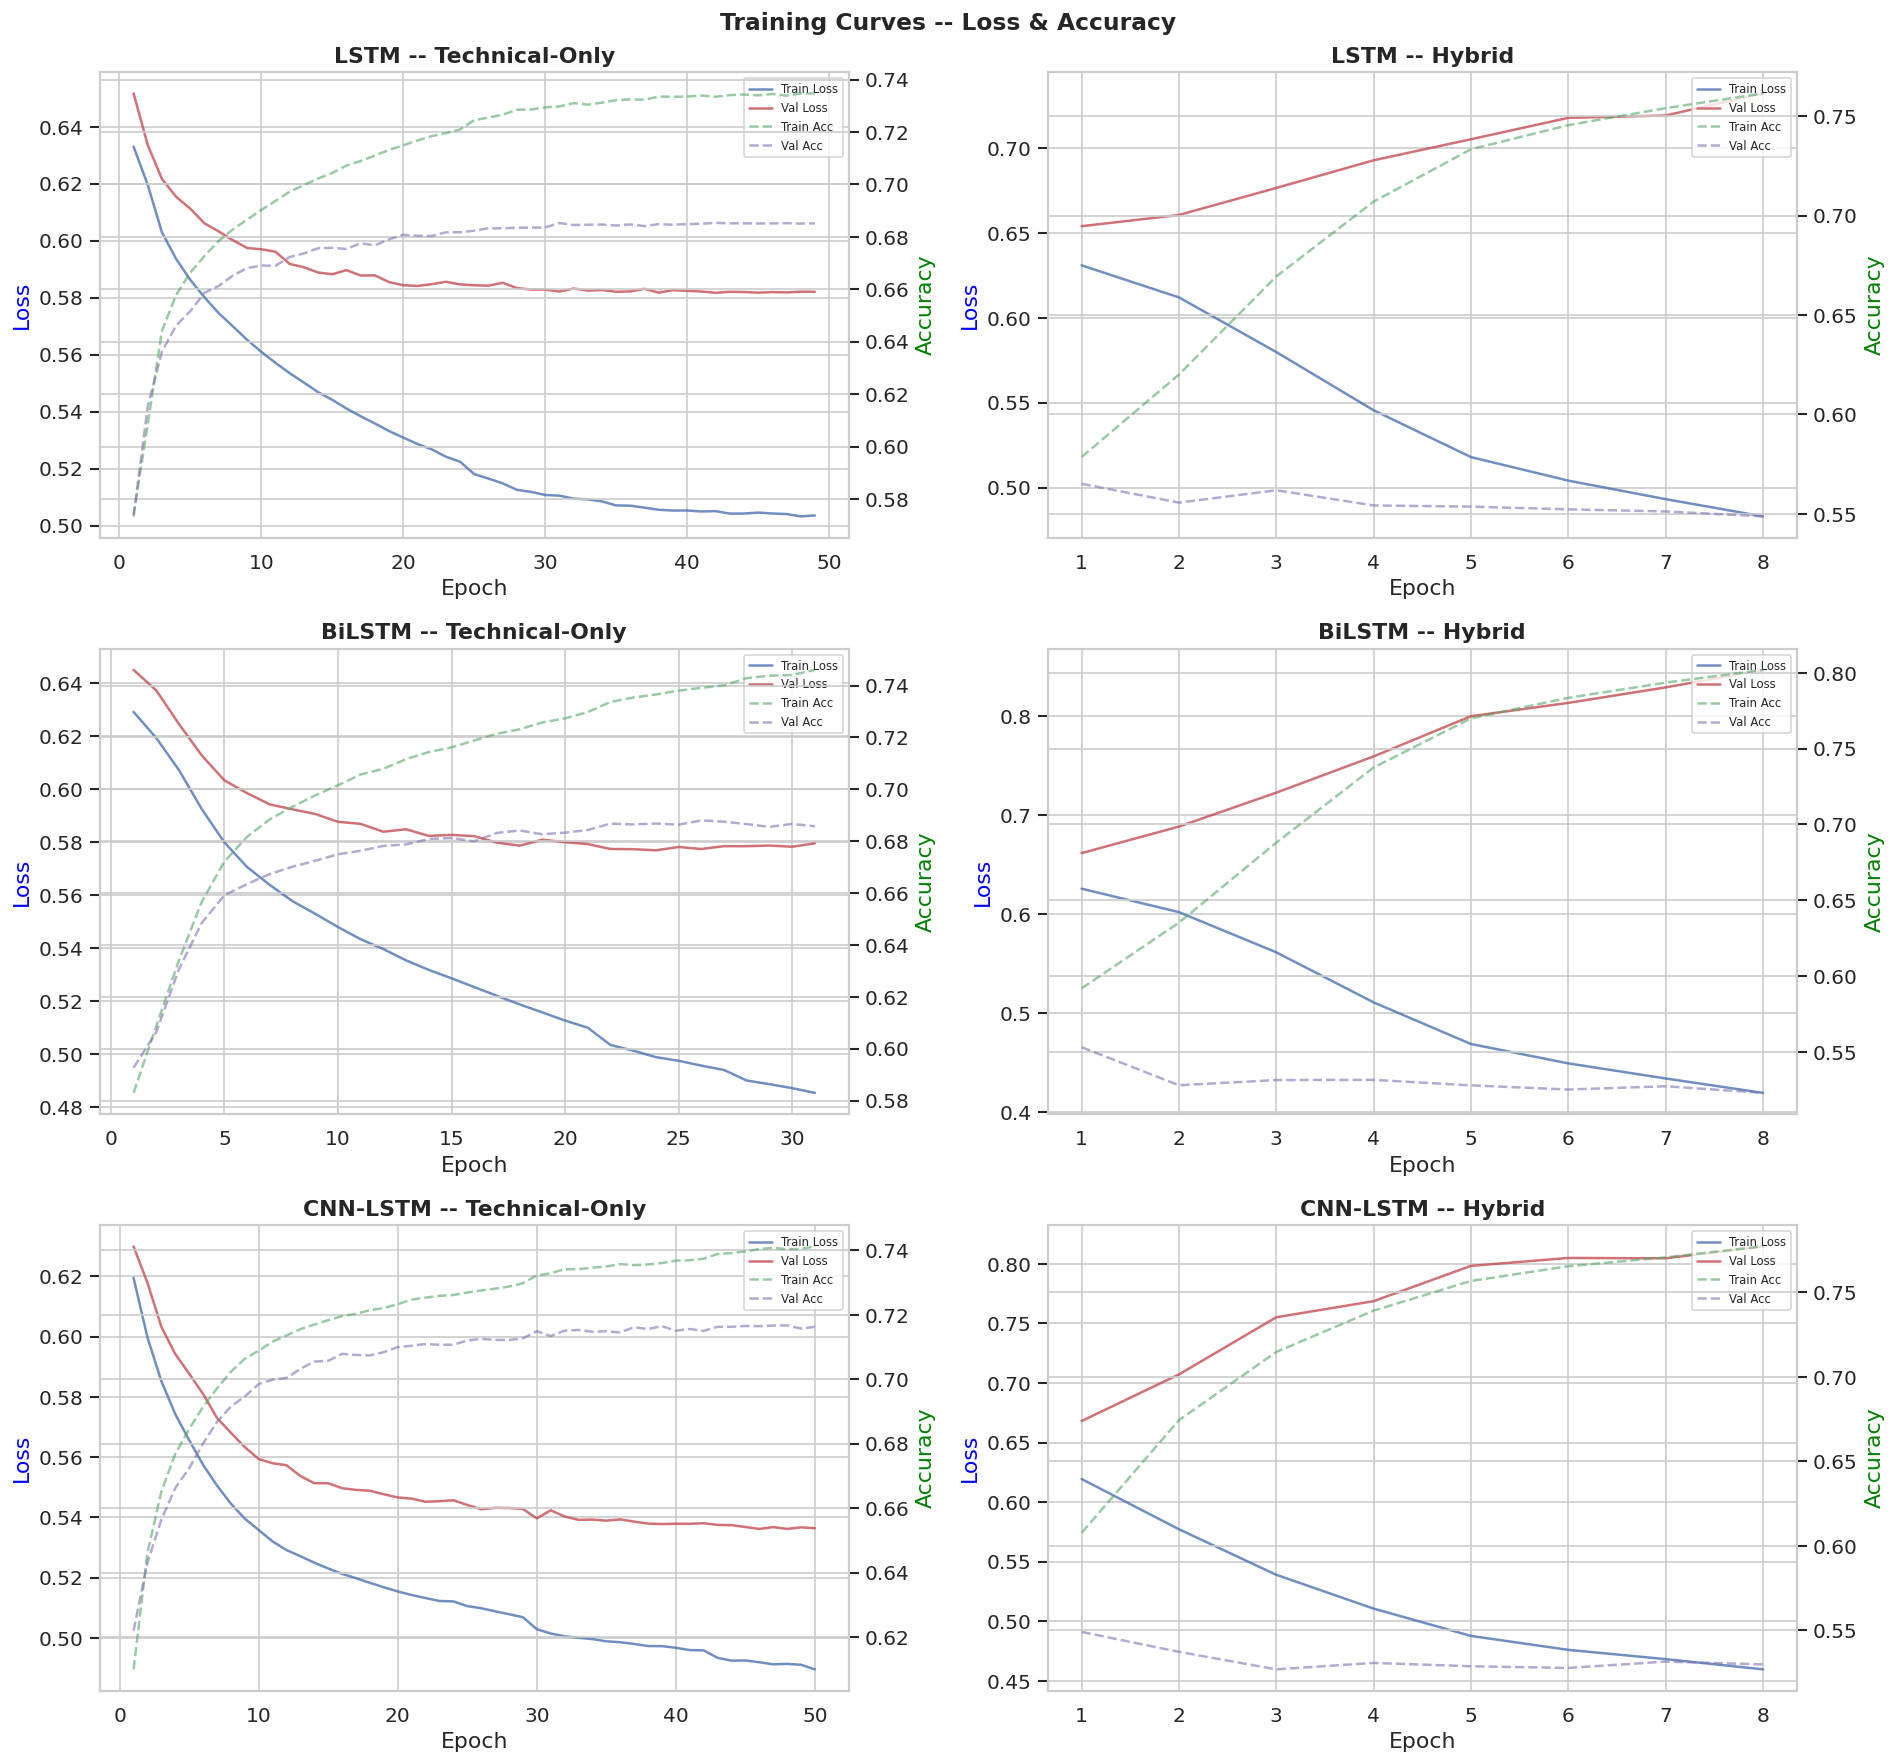

In [16]:
fig, axes = plt.subplots(3, 2, figsize=(16, 15))

plot_configs = [
    ('lstm_technical',    'lstm_hybrid',    'LSTM'),
    ('bilstm_technical',  'bilstm_hybrid',  'BiLSTM'),
    ('cnnlstm_technical', 'cnnlstm_hybrid', 'CNN-LSTM'),
]

for row, (tech_key, hybrid_key, name) in enumerate(plot_configs):
    for col, (key, config) in enumerate([(tech_key, 'Technical-Only'), (hybrid_key, 'Hybrid')]):
        ax = axes[row, col]
        h = histories[key]
        epochs_range = range(1, len(h.history['loss']) + 1)
        
        ax.plot(epochs_range, h.history['loss'], 'b-', label='Train Loss', alpha=0.8)
        ax.plot(epochs_range, h.history['val_loss'], 'r-', label='Val Loss', alpha=0.8)
        
        ax2 = ax.twinx()
        ax2.plot(epochs_range, h.history['accuracy'], 'g--', label='Train Acc', alpha=0.6)
        ax2.plot(epochs_range, h.history['val_accuracy'], 'm--', label='Val Acc', alpha=0.6)
        ax2.set_ylabel('Accuracy', color='green')
        
        ax.set_title(f'{name} -- {config}', fontweight='bold')
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Loss', color='blue')
        
        lines1, labels1 = ax.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        ax.legend(lines1 + lines2, labels1 + labels2, fontsize=7, loc='upper right')

fig.suptitle('Training Curves -- Loss & Accuracy', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'dl_training_curves.png'), bbox_inches='tight')
plt.show()

<a id='7'></a>
## 7. Results Summary

In [ ]:
results_df = pd.DataFrame(results)

display_df = results_df.copy()
display_df['Directional_Accuracy'] = display_df['Directional_Accuracy'].apply(lambda x: f'{x:.4f} ({x*100:.2f}%)')
display_df['Precision'] = display_df['Precision'].apply(lambda x: f'{x:.4f}')
display_df['Recall']    = display_df['Recall'].apply(lambda x: f'{x:.4f}')
display_df['F1_Score']  = display_df['F1_Score'].apply(lambda x: f'{x:.4f}')
display_df['Training_Time_s'] = display_df['Training_Time_s'].apply(lambda x: f'{x:.1f}s')

print('=' * 95)
print('  DEEP LEARNING RESULTS -- All Models x All Configurations')
print('=' * 95)
print(display_df.to_string(index=False))
print('=' * 95)

# Improvement Analysis
print('\n\n=== IMPROVEMENT ANALYSIS (Hybrid - Technical) ===\n')
for model_name in results_df['Model'].unique():
    tech = results_df[(results_df['Model']==model_name) & (results_df['Configuration']=='Technical-Only')]
    hyb  = results_df[(results_df['Model']==model_name) & (results_df['Configuration']=='Hybrid')]
    if len(tech) > 0 and len(hyb) > 0:
        t_acc = tech['Directional_Accuracy'].values[0]
        h_acc = hyb['Directional_Accuracy'].values[0]
        diff = (h_acc - t_acc) * 100
        threshold = 'YES' if diff >= 3.0 else 'No'
        print(f'  {model_name:15s}  Tech: {t_acc*100:.2f}%  ->  Hybrid: {h_acc*100:.2f}%  |  D = {diff:+.2f} pp  |  >=3pp: {threshold}')

  DEEP LEARNING RESULTS -- All Models x All Configurations
   Model  Configuration Directional_Accuracy Precision Recall F1_Score Training_Time_s  Epochs
    LSTM Technical-Only      0.6751 (67.51%)    0.6882 0.6751   0.6655          294.3s      49
    LSTM         Hybrid      0.5606 (56.06%)    0.5856 0.5606   0.5018           50.7s       8
  BiLSTM Technical-Only      0.6778 (67.78%)    0.6936 0.6778   0.6671          353.7s      31
  BiLSTM         Hybrid      0.5556 (55.56%)    0.5553 0.5556   0.5410           95.4s       8
CNN-LSTM Technical-Only      0.7076 (70.76%)    0.7404 0.7076   0.6934          291.4s      50
CNN-LSTM         Hybrid      0.5556 (55.56%)    0.5544 0.5556   0.5454           50.1s       8


=== IMPROVEMENT ANALYSIS (Hybrid - Technical) ===

  LSTM             Tech: 67.51%  ->  Hybrid: 56.06%  |  D = -11.45 pp  |  >=3pp: No
  BiLSTM           Tech: 67.78%  ->  Hybrid: 55.56%  |  D = -12.22 pp  |  >=3pp: No
  CNN-LSTM         Tech: 70.76%  ->  Hybrid: 55.56%  | 

<a id='8'></a>
## 8. Confusion Matrices

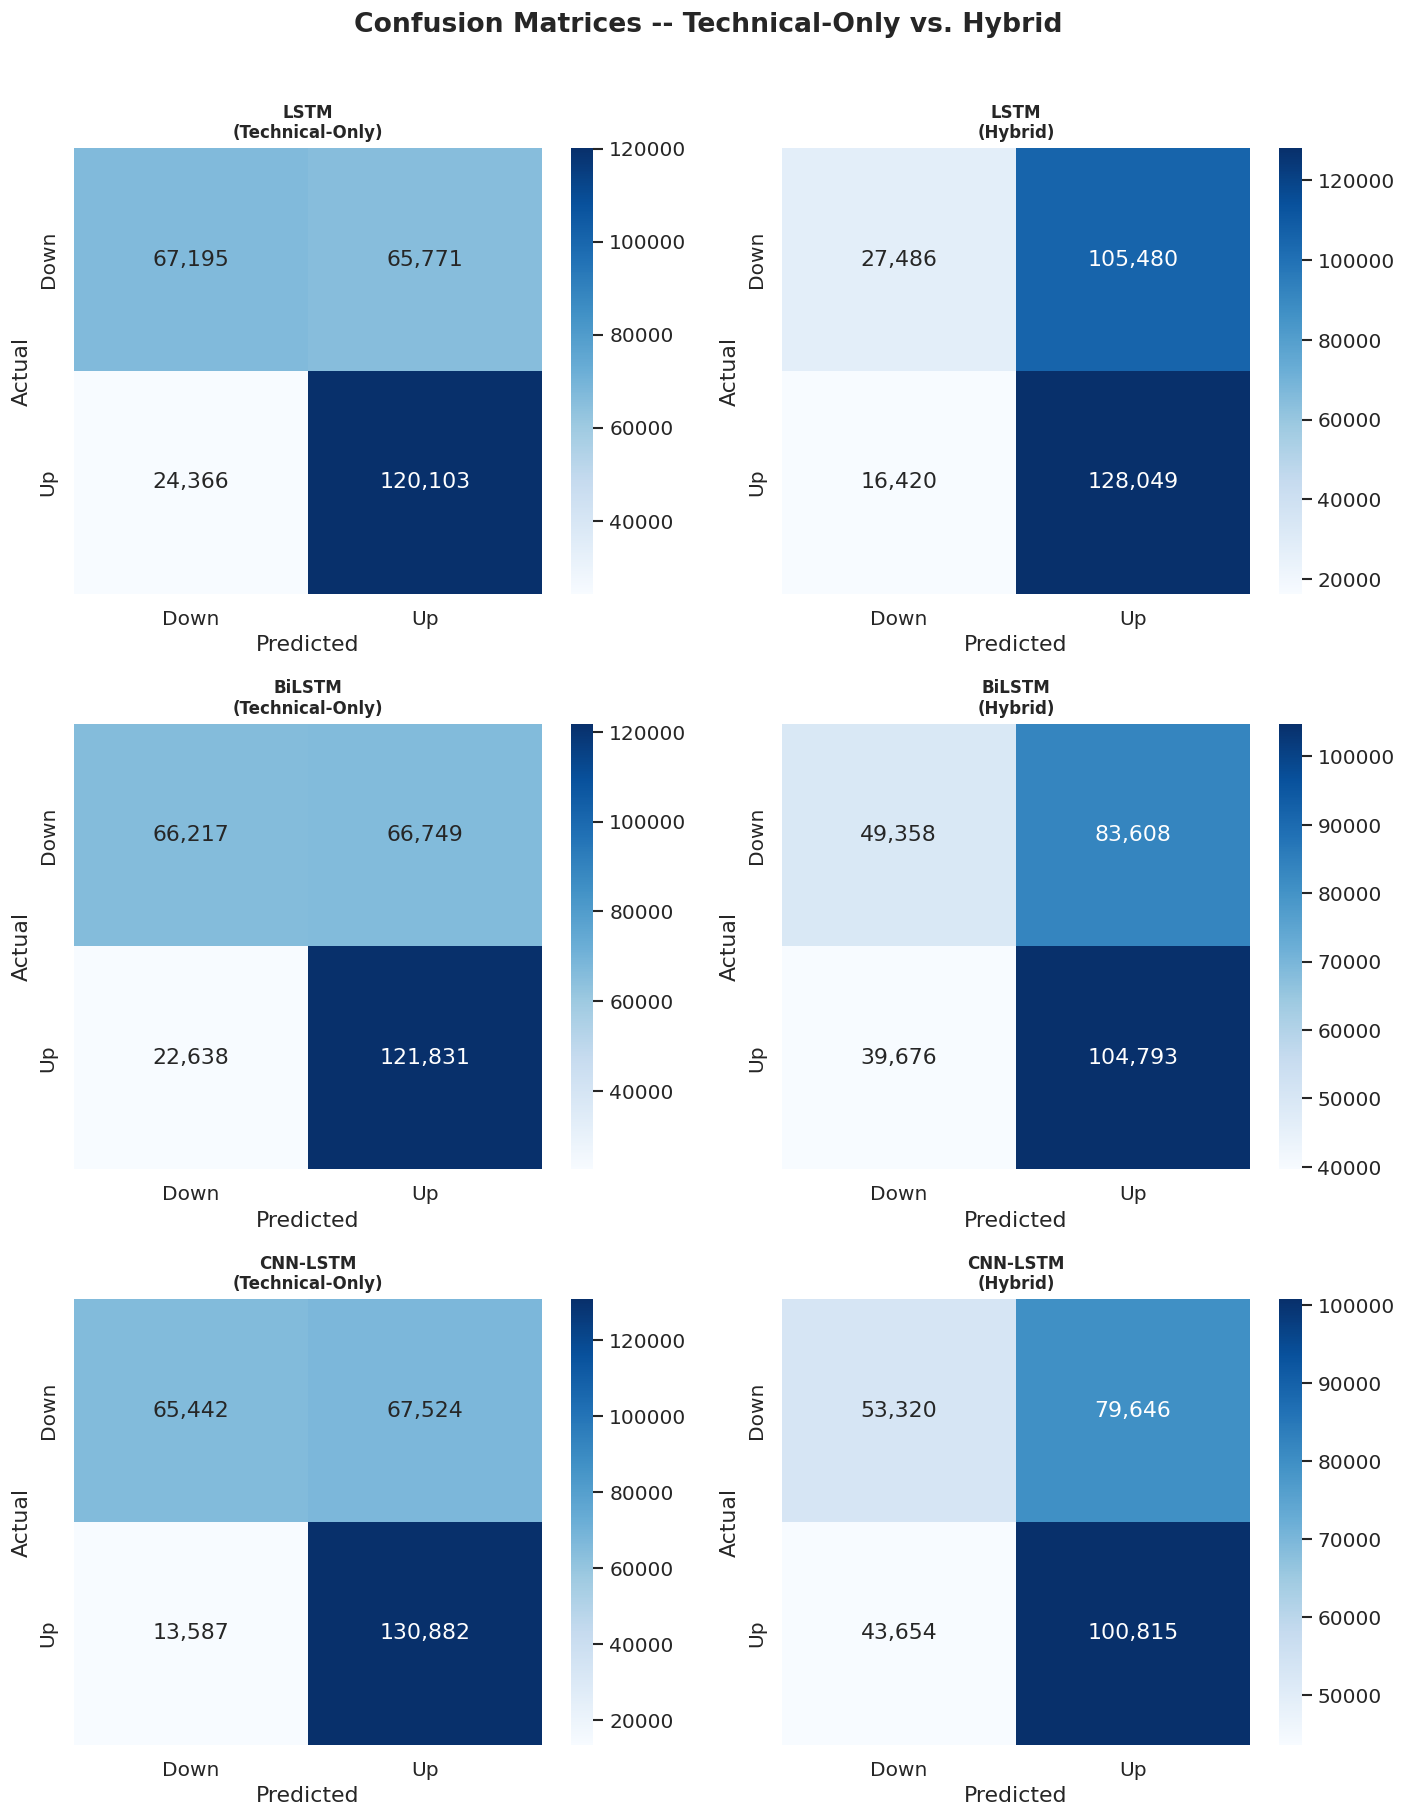

In [18]:
model_keys = [
    ('lstm_technical',    'lstm_hybrid',    'LSTM'),
    ('bilstm_technical',  'bilstm_hybrid',  'BiLSTM'),
    ('cnnlstm_technical', 'cnnlstm_hybrid', 'CNN-LSTM'),
]

fig, axes = plt.subplots(3, 2, figsize=(12, 15))
fig.suptitle('Confusion Matrices -- Technical-Only vs. Hybrid', fontsize=16, fontweight='bold', y=1.01)

for i, (tk, hk, name) in enumerate(model_keys):
    plot_confusion_matrix(y_test, predictions[tk], f'{name}\n(Technical-Only)', axes[i, 0])
    plot_confusion_matrix(y_test, predictions[hk], f'{name}\n(Hybrid)', axes[i, 1])

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'dl_confusion_matrices.png'), bbox_inches='tight')
plt.show()

## 9. Feature Importance (Permutation-Based Ablation)

Since deep learning models are not inherently interpretable like tree-based models, we use **permutation importance**: for each feature, we shuffle its values across all samples and time steps, then measure the drop in accuracy. A larger drop indicates higher importance.

This is performed on the **best-performing hybrid model** to identify which sentiment features contribute most to prediction.

Running permutation importance on: LSTM (Hybrid)
Baseline accuracy: 0.5606
  Daily_Return   : accuracy drop = +0.0005
  Open_Return    : accuracy drop = +0.0005
  High_Return    : accuracy drop = +0.0009
  Volume_Change  : accuracy drop = -0.0000
  SMA_5_Dist     : accuracy drop = +0.0052
  SMA_20_Dist    : accuracy drop = +0.0095
  RSI_14         : accuracy drop = +0.0473
  BB_Upper_Dist  : accuracy drop = +0.0010
  BB_Lower_Dist  : accuracy drop = +0.0004
  MACD           : accuracy drop = +0.0006
  neg            : accuracy drop = +0.0006
  neu            : accuracy drop = +0.0014
  pos            : accuracy drop = -0.0000
  compound       : accuracy drop = -0.0009
  polarity       : accuracy drop = +0.0008
  subjectivity   : accuracy drop = -0.0004


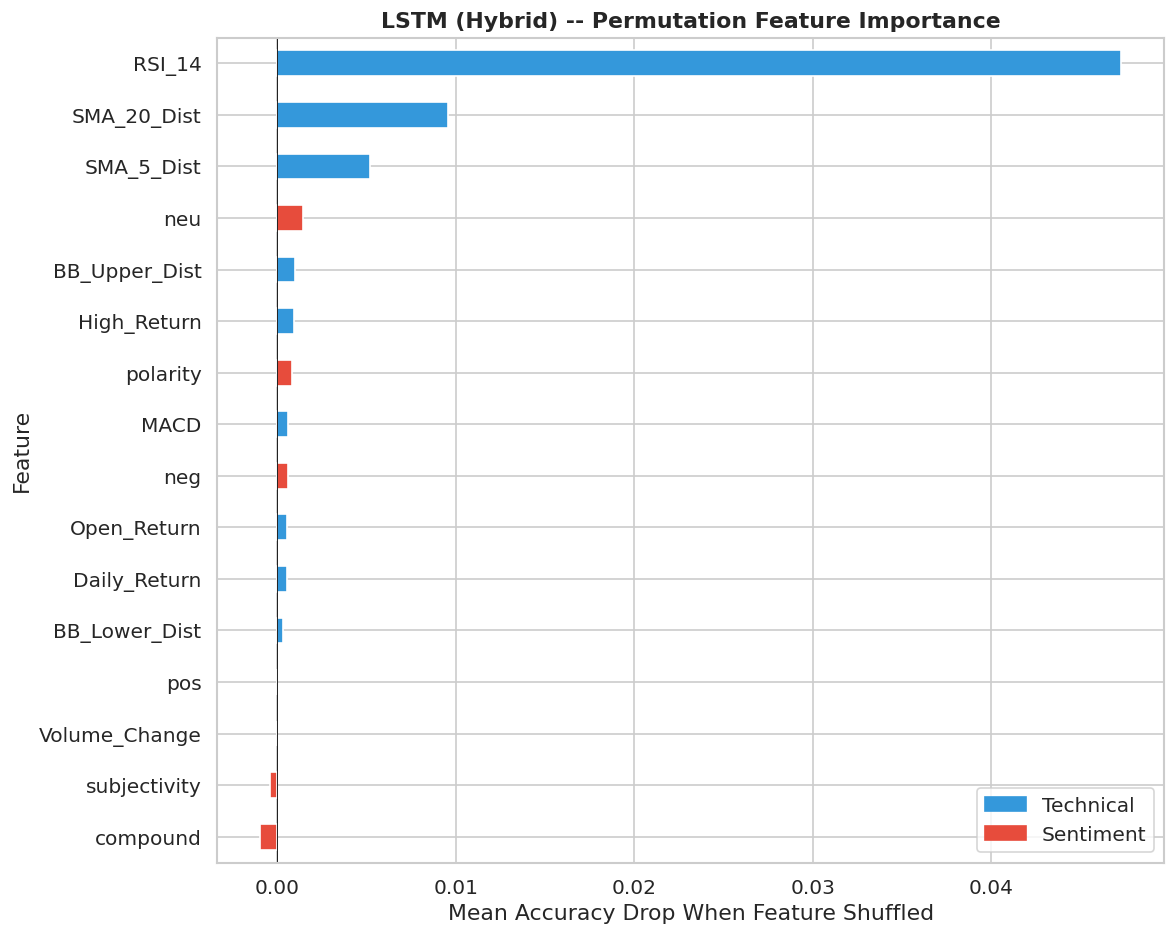


=== SENTIMENT FEATURE IMPORTANCE ===
  neg            : +0.000596
  neu            : +0.001421
  pos            : -0.000016
  compound       : -0.000940
  polarity       : +0.000818
  subjectivity   : -0.000425
CPU times: user 1min 17s, sys: 17.4 s, total: 1min 35s
Wall time: 1min 20s


In [19]:
%%time
# Select the best hybrid model for ablation
hybrid_results = results_df[results_df['Configuration'] == 'Hybrid']
best_hybrid_name = hybrid_results.loc[hybrid_results['Directional_Accuracy'].idxmax(), 'Model']
best_key = {'LSTM': 'lstm_hybrid', 'BiLSTM': 'bilstm_hybrid', 'CNN-LSTM': 'cnnlstm_hybrid'}[best_hybrid_name]
best_model = all_models[best_key]

print(f'Running permutation importance on: {best_hybrid_name} (Hybrid)')

# Baseline accuracy
baseline_pred = (best_model.predict(X_test_hybrid, batch_size=BATCH_SIZE, verbose=0).ravel() > 0.5).astype(int)
baseline_acc = accuracy_score(y_test, baseline_pred)
print(f'Baseline accuracy: {baseline_acc:.4f}')

# Permutation importance
n_repeats = 3
importances = {}

for feat_idx, feat_name in enumerate(HYBRID_FEATURES):
    drops = []
    for _ in range(n_repeats):
        X_perm = X_test_hybrid.copy()
        # Shuffle this feature across samples (for all time steps)
        perm_order = np.random.permutation(len(X_perm))
        X_perm[:, :, feat_idx] = X_perm[perm_order, :, feat_idx]
        
        perm_pred = (best_model.predict(X_perm, batch_size=BATCH_SIZE, verbose=0).ravel() > 0.5).astype(int)
        perm_acc = accuracy_score(y_test, perm_pred)
        drops.append(baseline_acc - perm_acc)
    
    importances[feat_name] = np.mean(drops)
    print(f'  {feat_name:15s}: accuracy drop = {np.mean(drops):+.4f}')

# Plot
imp_df = pd.DataFrame({'Feature': list(importances.keys()), 'Importance': list(importances.values())})
imp_df = imp_df.sort_values('Importance', ascending=True)

colors = ['#e74c3c' if f in SENTIMENT_FEATURES else '#3498db' for f in imp_df['Feature']]

fig, ax = plt.subplots(figsize=(10, 8))
imp_df.plot.barh(x='Feature', y='Importance', ax=ax, color=colors, legend=False)
ax.set_title(f'{best_hybrid_name} (Hybrid) -- Permutation Feature Importance', fontweight='bold')
ax.set_xlabel('Mean Accuracy Drop When Feature Shuffled')
ax.axvline(x=0, color='black', linewidth=0.5)

from matplotlib.patches import Patch
ax.legend(handles=[Patch(color='#3498db', label='Technical'),
                   Patch(color='#e74c3c', label='Sentiment')], loc='lower right')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'dl_feature_importance.png'), bbox_inches='tight')
plt.show()

print('\n=== SENTIMENT FEATURE IMPORTANCE ===')
for f in SENTIMENT_FEATURES:
    print(f'  {f:15s}: {importances.get(f, 0):+.6f}')

## 10. Statistical Significance -- Wilcoxon Signed-Rank Test

Rolling 3-month window comparison of Technical-Only vs. Hybrid accuracy, tested with the non-parametric Wilcoxon signed-rank test (p < 0.05).

In [ ]:
# Create Rolling 3-Month Windows
test_dates_sorted = np.sort(np.unique(dates_test))
window_size = pd.Timedelta(days=90)

windows = []
current_start = pd.Timestamp(test_dates_sorted[0])
end_date = pd.Timestamp(test_dates_sorted[-1])

while current_start < end_date:
    current_end = current_start + window_size
    mask = (dates_test >= np.datetime64(current_start)) & (dates_test < np.datetime64(current_end))
    if mask.sum() > 100:
        windows.append(mask)
    current_start = current_end

print(f'Number of 3-month windows: {len(windows)}')

# Wilcoxon Test
model_pairs = [
    ('LSTM',     'lstm_technical',    'lstm_hybrid'),
    ('BiLSTM',   'bilstm_technical',  'bilstm_hybrid'),
    ('CNN-LSTM', 'cnnlstm_technical', 'cnnlstm_hybrid'),
]

wilcoxon_results = []

print(f'\n{"="*80}')
print(f'{"WILCOXON SIGNED-RANK TEST RESULTS":^80}')
print(f'{"="*80}')

for model_name, tech_key, hybrid_key in model_pairs:
    tech_accs   = [accuracy_score(y_test[m], predictions[tech_key][m]) for m in windows]
    hybrid_accs = [accuracy_score(y_test[m], predictions[hybrid_key][m]) for m in windows]
    tech_accs   = np.array(tech_accs)
    hybrid_accs = np.array(hybrid_accs)
    mean_diff   = np.mean(hybrid_accs - tech_accs) * 100
    
    try:
        diffs = hybrid_accs - tech_accs
        if np.all(diffs == 0):
            stat, p_value = None, None
            significant = 'N/A (identical)'
        else:
            stat, p_value = wilcoxon(tech_accs, hybrid_accs, alternative='two-sided')
            significant = 'Yes' if p_value < 0.05 else 'No'
    except Exception as e:
        stat, p_value = None, None
        significant = f'N/A ({str(e)[:30]})'
    
    wilcoxon_results.append({
        'Model': model_name, 'N_Windows': len(tech_accs),
        'Mean_Tech_Acc': np.mean(tech_accs), 'Mean_Hybrid_Acc': np.mean(hybrid_accs),
        'Mean_Diff_pp': mean_diff, 'Wilcoxon_Stat': stat,
        'p_value': p_value, 'Significant_p05': significant
    })
    
    print(f'\n  {model_name}')
    print(f'  {"-"*40}')
    print(f'    Windows:          {len(tech_accs)}')
    print(f'    Mean Tech Acc:    {np.mean(tech_accs)*100:.2f}%')
    print(f'    Mean Hybrid Acc:  {np.mean(hybrid_accs)*100:.2f}%')
    print(f'    Mean Improvement: {mean_diff:+.2f} pp')
    if p_value is not None:
        print(f'    p-value:          {p_value:.6f}')
    print(f'    Significant:      {significant}')

wilcoxon_df = pd.DataFrame(wilcoxon_results)
print(f'\n{"="*80}')
print(wilcoxon_df.to_string(index=False))

Number of 3-month windows: 10

                       WILCOXON SIGNED-RANK TEST RESULTS                        

  LSTM
  ----------------------------------------
    Windows:          10
    Mean Tech Acc:    67.53%
    Mean Hybrid Acc:  56.08%
    Mean Improvement: -11.46 pp
    p-value:          0.001953
    Significant:      Yes

  BiLSTM
  ----------------------------------------
    Windows:          10
    Mean Tech Acc:    67.80%
    Mean Hybrid Acc:  55.57%
    Mean Improvement: -12.23 pp
    p-value:          0.001953
    Significant:      Yes

  CNN-LSTM
  ----------------------------------------
    Windows:          10
    Mean Tech Acc:    70.78%
    Mean Hybrid Acc:  55.56%
    Mean Improvement: -15.23 pp
    p-value:          0.001953
    Significant:      Yes

   Model  N_Windows  Mean_Tech_Acc  Mean_Hybrid_Acc  Mean_Diff_pp  Wilcoxon_Stat  p_value Significant_p05
    LSTM         10       0.675323         0.560763    -11.456057            0.0 0.001953             Yes


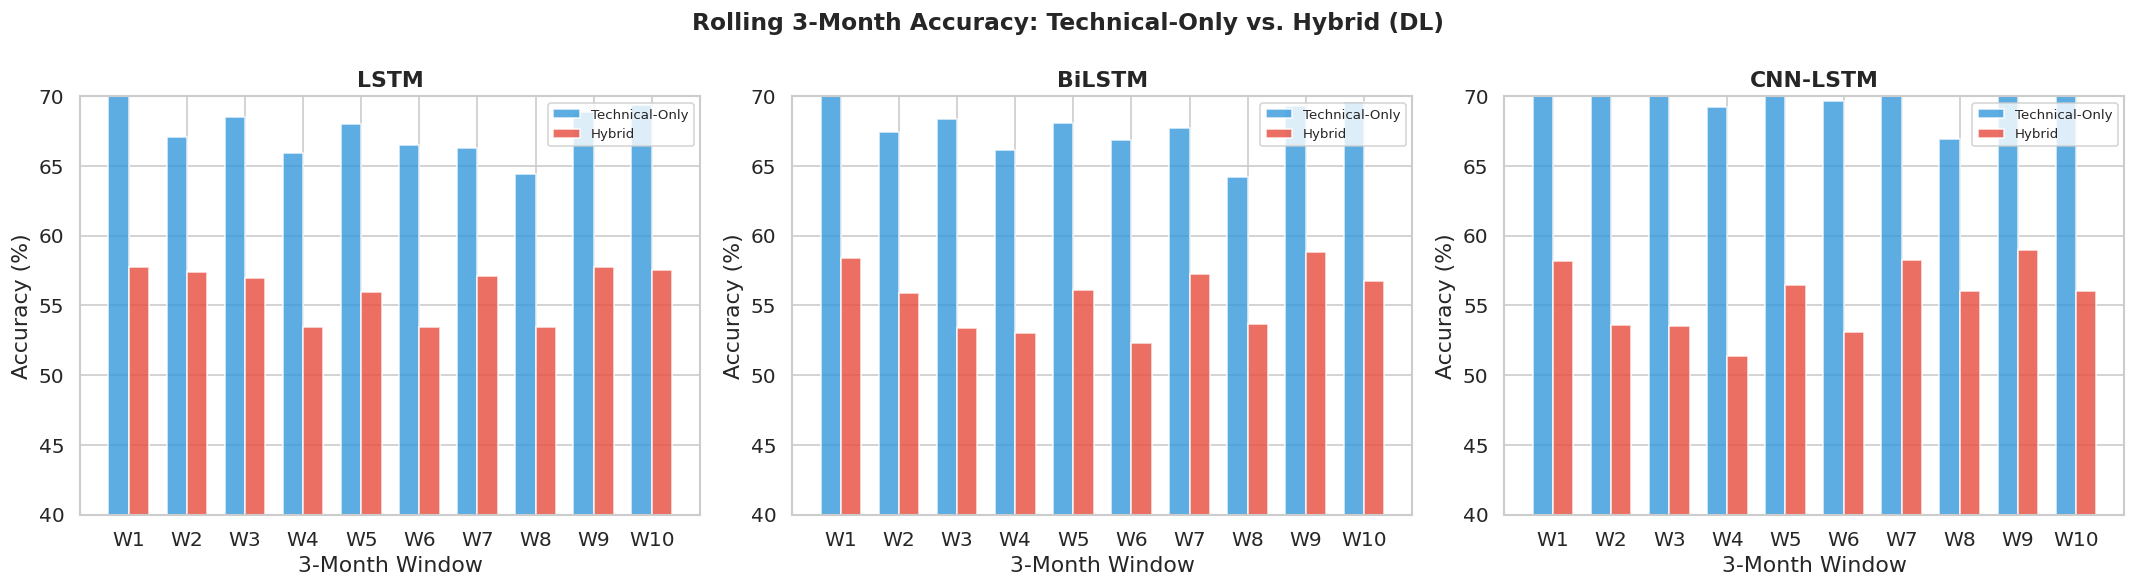

In [ ]:
# Rolling Window Accuracy Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
window_labels = [f'W{i+1}' for i in range(len(windows))]

for idx, (model_name, tk, hk) in enumerate(model_pairs):
    ax = axes[idx]
    t_a = [accuracy_score(y_test[m], predictions[tk][m])*100 for m in windows]
    h_a = [accuracy_score(y_test[m], predictions[hk][m])*100 for m in windows]
    x = np.arange(len(windows))
    w = 0.35
    ax.bar(x - w/2, t_a, w, label='Technical-Only', color='#3498db', alpha=0.8)
    ax.bar(x + w/2, h_a, w, label='Hybrid', color='#e74c3c', alpha=0.8)
    ax.set_title(model_name, fontweight='bold')
    ax.set_xlabel('3-Month Window')
    ax.set_ylabel('Accuracy (%)')
    ax.set_xticks(x)
    ax.set_xticklabels(window_labels)
    ax.legend(fontsize=8)
    ax.set_ylim(40, 70)

fig.suptitle('Rolling 3-Month Accuracy: Technical-Only vs. Hybrid (DL)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'dl_rolling_window_accuracy.png'), bbox_inches='tight')
plt.show()

<a id='11'></a>
## 11. Comparative Visualisations

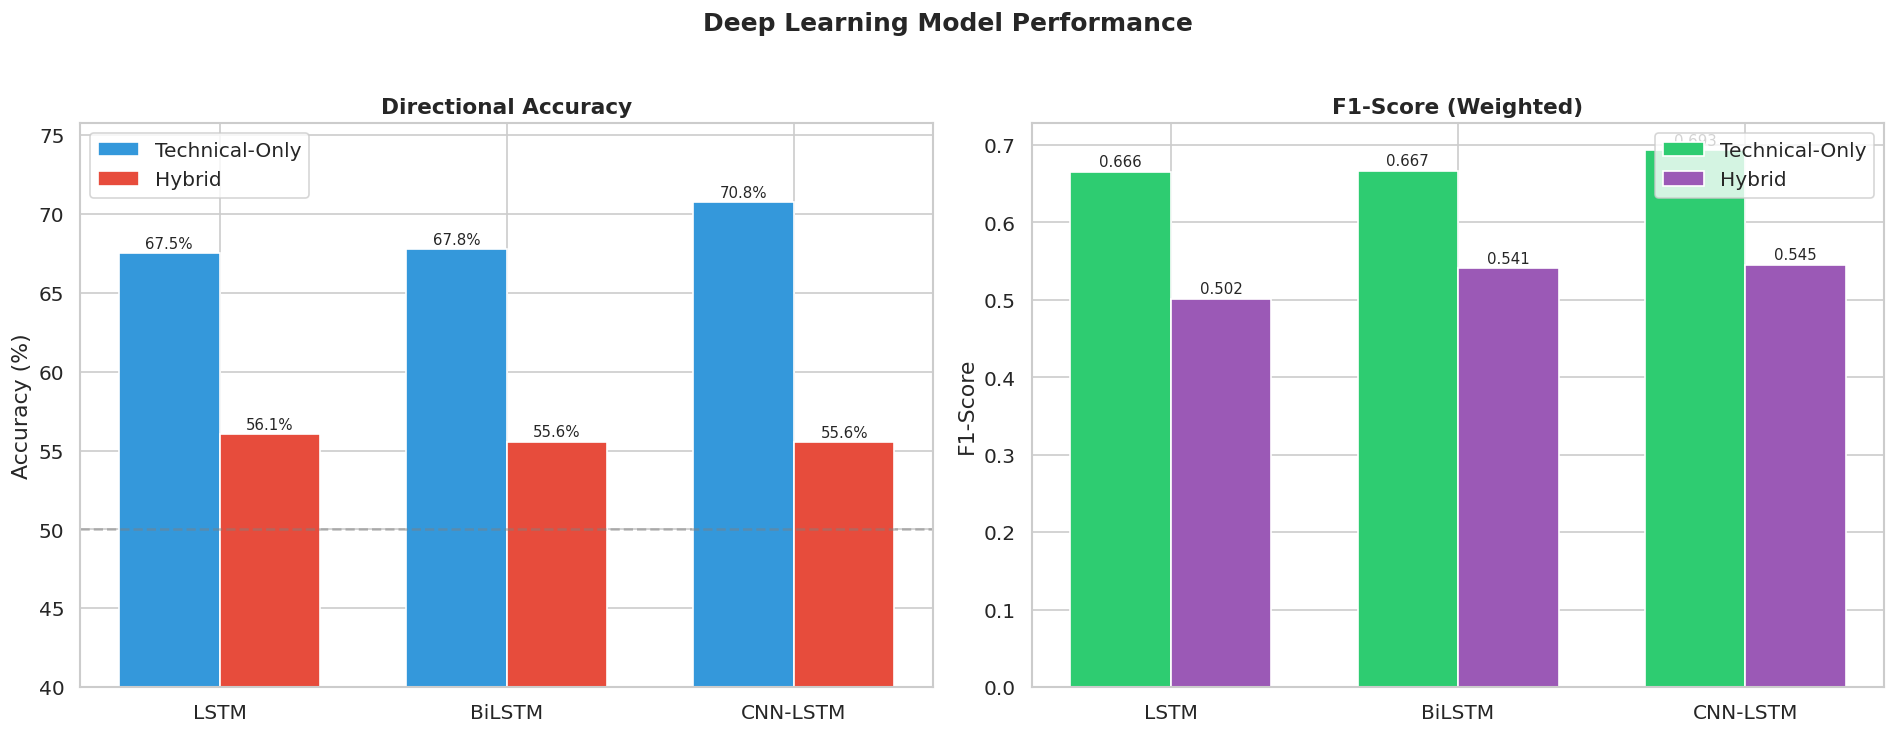

In [ ]:
# Accuracy & F1 Comparison Bar Charts
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
models_order = ['LSTM', 'BiLSTM', 'CNN-LSTM']

tech_acc = [results_df[(results_df['Model']==m)&(results_df['Configuration']=='Technical-Only')]['Directional_Accuracy'].values[0]*100 for m in models_order]
hyb_acc  = [results_df[(results_df['Model']==m)&(results_df['Configuration']=='Hybrid')]['Directional_Accuracy'].values[0]*100 for m in models_order]

x = np.arange(len(models_order))
w = 0.35

b1 = axes[0].bar(x-w/2, tech_acc, w, label='Technical-Only', color='#3498db', edgecolor='white')
b2 = axes[0].bar(x+w/2, hyb_acc, w, label='Hybrid', color='#e74c3c', edgecolor='white')
for b in b1:
    axes[0].annotate(f'{b.get_height():.1f}%', xy=(b.get_x()+b.get_width()/2, b.get_height()), xytext=(0,3), textcoords='offset points', ha='center', fontsize=9)
for b in b2:
    axes[0].annotate(f'{b.get_height():.1f}%', xy=(b.get_x()+b.get_width()/2, b.get_height()), xytext=(0,3), textcoords='offset points', ha='center', fontsize=9)
axes[0].set_title('Directional Accuracy', fontweight='bold', fontsize=13)
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_xticks(x)
axes[0].set_xticklabels(models_order)
axes[0].legend()
axes[0].axhline(y=50, color='gray', linestyle='--', alpha=0.5)
axes[0].set_ylim(40, max(max(tech_acc), max(hyb_acc)) + 5)

tech_f1 = [results_df[(results_df['Model']==m)&(results_df['Configuration']=='Technical-Only')]['F1_Score'].values[0] for m in models_order]
hyb_f1  = [results_df[(results_df['Model']==m)&(results_df['Configuration']=='Hybrid')]['F1_Score'].values[0] for m in models_order]

b1 = axes[1].bar(x-w/2, tech_f1, w, label='Technical-Only', color='#2ecc71', edgecolor='white')
b2 = axes[1].bar(x+w/2, hyb_f1, w, label='Hybrid', color='#9b59b6', edgecolor='white')
for b in b1:
    axes[1].annotate(f'{b.get_height():.3f}', xy=(b.get_x()+b.get_width()/2, b.get_height()), xytext=(0,3), textcoords='offset points', ha='center', fontsize=9)
for b in b2:
    axes[1].annotate(f'{b.get_height():.3f}', xy=(b.get_x()+b.get_width()/2, b.get_height()), xytext=(0,3), textcoords='offset points', ha='center', fontsize=9)
axes[1].set_title('F1-Score (Weighted)', fontweight='bold', fontsize=13)
axes[1].set_ylabel('F1-Score')
axes[1].set_xticks(x)
axes[1].set_xticklabels(models_order)
axes[1].legend()

plt.suptitle('Deep Learning Model Performance', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'dl_model_comparison.png'), bbox_inches='tight')
plt.show()

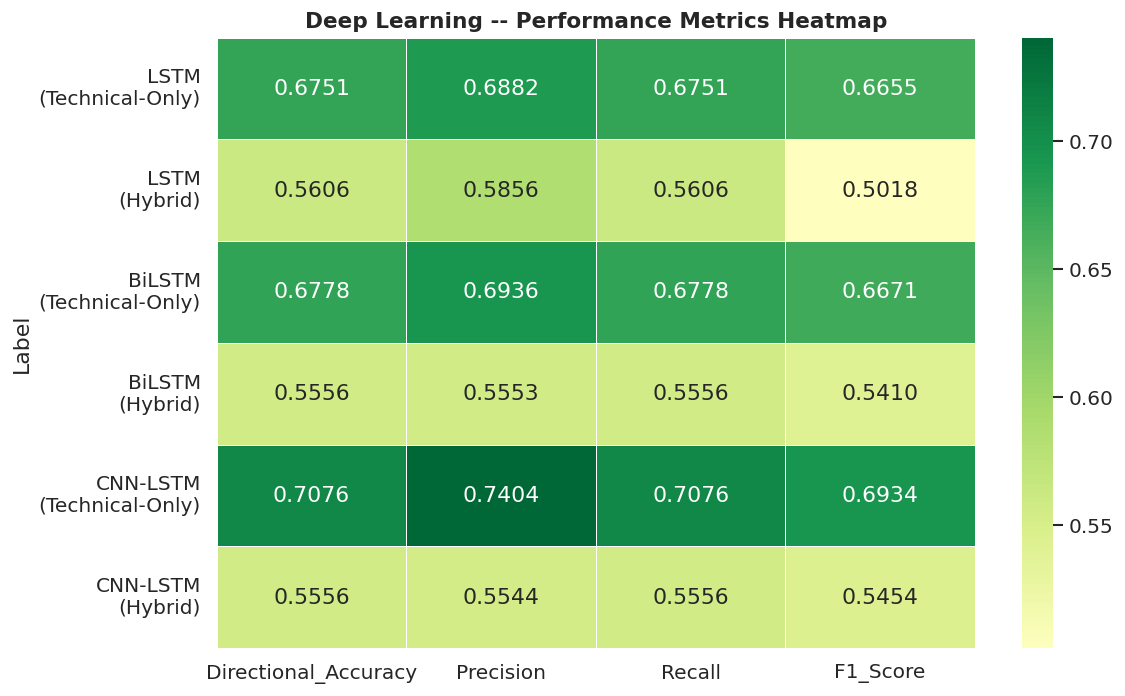

In [ ]:
# Metrics Heatmap
hm = results_df.copy()
hm['Label'] = hm['Model'] + '\n(' + hm['Configuration'] + ')'
hm_metrics = hm[['Label','Directional_Accuracy','Precision','Recall','F1_Score']].set_index('Label')

plt.figure(figsize=(10, 6))
sns.heatmap(hm_metrics.astype(float), annot=True, fmt='.4f', cmap='RdYlGn', center=0.5,
            linewidths=0.5, linecolor='white')
plt.title('Deep Learning -- Performance Metrics Heatmap', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'dl_metrics_heatmap.png'), bbox_inches='tight')
plt.show()

## 12. Model Saving

All 6 trained deep learning models are saved in Keras `.keras` format. Metadata and results are saved as JSON/CSV.

In [24]:
MODELS_DIR = os.path.join(OUTPUT_DIR, 'saved_models_dl')
os.makedirs(MODELS_DIR, exist_ok=True)

print('Saving trained deep learning models...\n')

for model_key, model_obj in all_models.items():
    filepath = os.path.join(MODELS_DIR, f'{model_key}.keras')
    model_obj.save(filepath)
    file_size = os.path.getsize(filepath) / (1024 * 1024)
    print(f'  Saved {model_key:25s} -> {filepath}  ({file_size:.1f} MB)')

# Metadata
metadata = {
    'technical_features': TECHNICAL_FEATURES,
    'sentiment_features': SENTIMENT_FEATURES,
    'hybrid_features': HYBRID_FEATURES,
    'sequence_length': SEQ_LEN,
    'target_column': TARGET,
    'split_date': str(split_date),
    'val_split_date': str(val_split_date),
    'epochs': EPOCHS,
    'batch_size': BATCH_SIZE,
    'model_keys': list(all_models.keys())
}
meta_path = os.path.join(MODELS_DIR, 'dl_model_metadata.json')
with open(meta_path, 'w') as f:
    json_mod.dump(metadata, f, indent=2)
print(f'\n  Saved metadata -> {meta_path}')

# Results
res_path = os.path.join(OUTPUT_DIR, 'dl_model_results.csv')
results_df.to_csv(res_path, index=False)
print(f'  Saved results  -> {res_path}')

wil_path = os.path.join(OUTPUT_DIR, 'dl_wilcoxon_results.csv')
wilcoxon_df.to_csv(wil_path, index=False)
print(f'  Saved Wilcoxon -> {wil_path}')

print(f'\nAll {len(all_models)} models and metadata saved!')

Saving trained deep learning models...

  Saved lstm_technical            -> /kaggle/working/saved_models_dl/lstm_technical.keras  (1.4 MB)
  Saved lstm_hybrid               -> /kaggle/working/saved_models_dl/lstm_hybrid.keras  (1.5 MB)
  Saved bilstm_technical          -> /kaggle/working/saved_models_dl/bilstm_technical.keras  (3.6 MB)
  Saved bilstm_hybrid             -> /kaggle/working/saved_models_dl/bilstm_hybrid.keras  (3.7 MB)
  Saved cnnlstm_technical         -> /kaggle/working/saved_models_dl/cnnlstm_technical.keras  (1.0 MB)
  Saved cnnlstm_hybrid            -> /kaggle/working/saved_models_dl/cnnlstm_hybrid.keras  (1.0 MB)

  Saved metadata -> /kaggle/working/saved_models_dl/dl_model_metadata.json
  Saved results  -> /kaggle/working/dl_model_results.csv
  Saved Wilcoxon -> /kaggle/working/dl_wilcoxon_results.csv

All 6 models and metadata saved!


## 13. Verification -- Load & Test Saved Models

In [25]:
print('Verifying saved models...\n')

with open(os.path.join(MODELS_DIR, 'dl_model_metadata.json'), 'r') as f:
    loaded_meta = json_mod.load(f)

print(f'Sequence length: {loaded_meta["sequence_length"]}')
print(f'Model keys: {loaded_meta["model_keys"]}')

X_sample_tech   = X_test_tech[:200]
X_sample_hybrid = X_test_hybrid[:200]

all_match = True
for model_key in loaded_meta['model_keys']:
    loaded = load_model(os.path.join(MODELS_DIR, f'{model_key}.keras'))
    X_sample = X_sample_tech if 'technical' in model_key else X_sample_hybrid
    loaded_preds = (loaded.predict(X_sample, verbose=0).ravel() > 0.5).astype(int)
    original_preds = predictions[model_key][:200]
    match = np.array_equal(loaded_preds, original_preds)
    status = 'MATCH' if match else 'MISMATCH'
    if not match:
        all_match = False
    print(f'  {model_key:25s}: {status}')

print(f'\n{"="*60}')
if all_match:
    print('  ALL MODELS VERIFIED -- predictions match.')
else:
    print('  Some models differ (may be due to GPU non-determinism).')
print(f'{"="*60}')

Verifying saved models...

Sequence length: 10
Model keys: ['lstm_technical', 'lstm_hybrid', 'bilstm_technical', 'bilstm_hybrid', 'cnnlstm_technical', 'cnnlstm_hybrid']
  lstm_technical           : MATCH
  lstm_hybrid              : MATCH
  bilstm_technical         : MATCH
  bilstm_hybrid            : MATCH
  cnnlstm_technical        : MATCH
  cnnlstm_hybrid           : MATCH

  ALL MODELS VERIFIED -- predictions match.
